# Search-02d : Recherche continue — RRT et RRT* (planification par échantillonnage)

**Navigation** : [<< QuikGraph (02c)](Search-02c-QuikGraph.ipynb) | [Index](../README.md) | [Recherche informée (03) >>](Search-03-Informed.ipynb)

**Série** : Search / Part1-Foundations
**Durée estimée** : ~45 min
**Prérequis** : Search-02 (espaces d'états, BFS/UCS), un peu de géométrie analytique

Jusqu'ici, la série a travaillé sur des **espaces d'états discrets** : grilles, puzzles, graphes de villes. La planification robotique pose le même problème — trouver un chemin bon marché d'un état à un autre — mais dans un **espace continu** : le robot est un point du plan, et son voisinage est infini. On n'y énumère plus les états : on les **échantillonne**.

Ce notebook implémente from scratch (stdlib + numpy + matplotlib) les deux algorithmes fondateurs de la famille :

- **RRT** (*Rapidly-exploring Random Tree*, LaValle 1998) — complet, mais ses chemins zigzaguent ;
- **RRT\*** (Karaman & Frazzoli 2011) — ajoute une étape de *rewiring* qui rend l'algorithme **asymptotiquement optimal** : le chemin converge vers l'optimum quand le nombre d'échantillons croît.

La question du carnet : **que rapporte concrètement le rewiring ?** On ne se contente pas de l'affirmer : on le mesure (longueur de chemin en fonction du budget d'échantillons, plusieurs graines).


In [1]:
import math
import random

import matplotlib.pyplot as plt
import numpy as np

plt.rcParams['figure.figsize'] = (7, 7)
print("imports OK : numpy", np.__version__)

imports OK : numpy 2.3.5


## 1. Le terrain : un rectangle et des obstacles

Le monde est le carré $[0, 10]^2$. Le robot est un point ; un point est **bloqué** s'il sort du carré ou s'il tombe dans un des trois rectangles obstacles. Toute la géométrie du problème tient dans la fonction `est_bloque` — les algorithmes ne voient que cette prédicat.


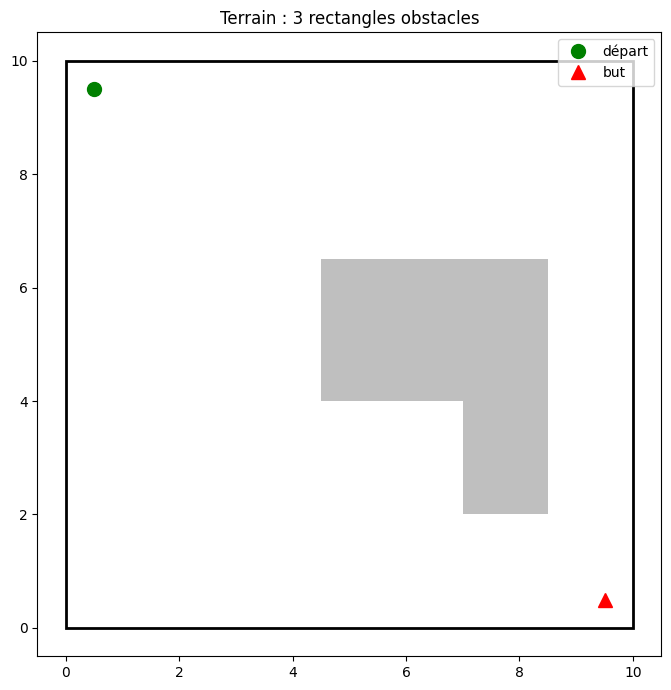

In [2]:
# --- Le terrain ---
BOITE = (0.0, 10.0)
OBSTACLES = [
    (2.0, 1.0, 2.0, 6.0),   # (x_min, y_min, x_max, y_max)
    (4.5, 4.0, 4.5 + 3.0, 4.0 + 2.5),
    (7.0, 2.0, 7.0 + 1.5, 2.0 + 4.5),
]

def est_bloque(p):
    """Un point est bloque s'il est hors de la boite ou dans un obstacle."""
    x, y = p
    if not (BOITE[0] <= x <= BOITE[1] and BOITE[0] <= y <= BOITE[1]):
        return True
    for x0, y0, x1, y1 in OBSTACLES:
        if x0 <= x <= x1 and y0 <= y <= y1:
            return True
    return False

DEPART = (0.5, 9.5)
BUT = (9.5, 0.5)

fig, ax = plt.subplots()
ax.add_patch(plt.Rectangle((0, 0), 10, 10, fill=False, lw=2, ec='k'))
for x0, y0, x1, y1 in OBSTACLES:
    ax.add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fc='0.75'))
ax.plot(*DEPART, 'go', ms=10, label='départ')
ax.plot(*BUT, 'r^', ms=10, label='but')
ax.set_xlim(-0.5, 10.5); ax.set_ylim(-0.5, 10.5)
ax.set_aspect('equal'); ax.legend(); ax.set_title('Terrain : 3 rectangles obstacles')
plt.tight_layout(); plt.show()

### Lecture du résultat

Le départ (en haut à gauche) et le but (en bas à droite) sont séparés par un **goulet** entre les deux premiers obstacles. La distance à vol d'oiseau $\|d - b\|$ est la **borne inférieure** de toute trajectoire : c'est le dénominateur contre lequel on mesurera la qualité des chemins trouvés.


In [3]:
def dist(a, b):
    return math.hypot(a[0] - b[0], a[1] - b[1])

BORNE_INF = dist(DEPART, BUT)
print(f"borne inférieure (à vol d'oiseau) : {BORNE_INF:.2f}")

def segment_bloque(a, b, bloque=est_bloque, echantillons=None):
    """Vrai si un point echantillonne du segment [a, b] est bloque.

    Le nombre d'echantillons suit la longueur (pas de 0.05) : un compte fixe
    laisserait passer un obstacle etroit traverse en biais par un long segment.
    """
    if echantillons is None:
        echantillons = max(5, int(dist(a, b) / 0.05))
    for k in range(echantillons + 1):
        t = k / echantillons
        if bloque((a[0] + t * (b[0] - a[0]), a[1] + t * (b[1] - a[1]))):
            return True
    return False

borne inférieure (à vol d'oiseau) : 12.73


## 2. RRT : faire pousser un arbre vers le but

L'idée de LaValle : au lieu d'explorer systématiquement, **tire un point au hasard**, rattache-le au **plus proche** nœud de l'arbre (en avançant d'un pas borné $r$), et répète. L'arbre « accourt » naturellement vers les grandes régions vides — c'est ce qui rend l'exploration *rapide* (*rapidly-exploring*).

Deux détails pratiques :

- **pas borné** ($r = 0.5$ ici) : on ne rattache que partiellement, l'arbre progresse en petits pas ;
- **biais vers le but** (probabilité $0.1$) : sans lui, l'arbre met très longtemps à « tomber » sur le but ;
- **validité du segment** : le bord parent → nouveau nœud doit lui-même éviter les obstacles (contrôle par échantillonnage) — sans lui, un pas de 0.5 sauterait une paroi fine.


RRT : 1210 noeuds, longueur 16.12 (ratio vs borne inf. : 1.27x)


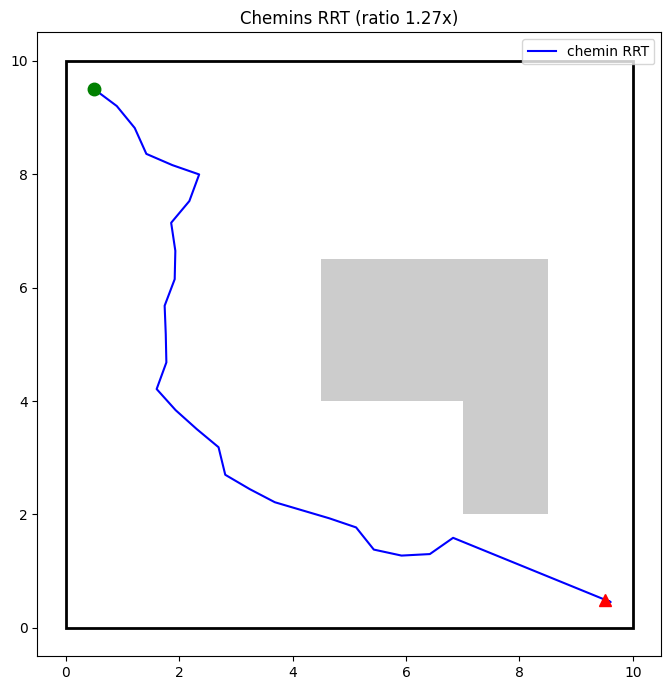

In [4]:
# --- RRT classique (LaValle 1998) ---
def rrt_plan(depart, but, max_iter=2000, pas=0.5, biais=0.1, rng=None, bloque=None):
    """RRT classique, execute sur le budget entier. Retourne {'chemin', 'noeuds'}."""
    rng = rng or random.Random()
    bloque = bloque or est_bloque
    noeuds = [depart]
    parent = [-1]
    meilleur, meilleur_chemin = None, None

    def plus_proche(p):
        return min(range(len(noeuds)), key=lambda i: dist(noeuds[i], p))

    for _ in range(max_iter):
        cible = but if rng.random() < biais else (rng.uniform(*BOITE), rng.uniform(*BOITE))
        i = plus_proche(cible)
        m = dist(noeuds[i], cible)
        pas_xy = (pas / m * (cible[0] - noeuds[i][0]),
                  pas / m * (cible[1] - noeuds[i][1])) if m > 1e-9 else (0.0, 0.0)
        q = (noeuds[i][0] + pas_xy[0], noeuds[i][1] + pas_xy[1])
        # le nœud ET le segment parent -> q doivent etre libres
        # (sans ce controle, un pas de 0.5 sauterait une paroi fine)
        if bloque(q) or segment_bloque(noeuds[i], q, bloque):
            continue
        parent.append(i)
        noeuds.append(q)
        if dist(q, but) < 0.3:
            # chemin depart -> but (on ne s'arrete pas : le budget continue de s'executer)
            chemin, j = [q], len(noeuds) - 1
            while parent[j] != -1:
                j = parent[j]
                chemin.append(noeuds[j])
            chemin.reverse()
            # le chemin s'arrete au noeud d'attrait q, pas au but exact :
            # on complete par le segment q -> but s'il est libre (zone degagee)
            if not segment_bloque(q, but, bloque):
                chemin.append(but)
            if meilleur is None or longueur(chemin) < meilleur:
                meilleur = longueur(chemin)
                meilleur_chemin = chemin
    return {"chemin": meilleur_chemin, "noeuds": len(noeuds)}

def longueur(chemin):
    return sum(dist(chemin[k], chemin[k + 1]) for k in range(len(chemin) - 1))

res = rrt_plan(DEPART, BUT, max_iter=1500, rng=random.Random(0))
chemin = res['chemin']
print(f"RRT : {res['noeuds']} noeuds, longueur {longueur(chemin):.2f} "
      f"(ratio vs borne inf. : {longueur(chemin) / BORNE_INF:.2f}x)")

fig, ax = plt.subplots()
ax.add_patch(plt.Rectangle((0, 0), 10, 10, fill=False, lw=2, ec='k'))
for x0, y0, x1, y1 in OBSTACLES:
    ax.add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fc='0.8'))
xs, ys = zip(*chemin)
ax.plot(xs, ys, 'b-', lw=1.5, label='chemin RRT')
ax.plot(*DEPART, 'go', ms=9); ax.plot(*BUT, 'r^', ms=9)
ax.set_xlim(-0.5, 10.5); ax.set_ylim(-0.5, 10.5)
ax.set_aspect('equal'); ax.legend()
ax.set_title(f'Chemins RRT (ratio {longueur(chemin) / BORNE_INF:.2f}x)')
plt.tight_layout(); plt.show()

### Lecture du résultat

Le chemin existe, il est valide — mais regardez les coudes : le RRT a rattaché chaque nouveau nœud au plus proche voisin **sans jamais réexaminer** les décisions prises plus tôt. Le ratio contre la borne inférieure est le chiffre à retenir : c'est la **dette de qualité** que le RRT classique laisse sur la table.


## 3. RRT* : le rewiring, ou réviser ses décisions

RRT\* (Karaman & Frazzoli 2011) modifie la règle d'insertion :

1. **choix du parent** — au lieu de prendre le plus proche nœud, on regarde tous les nœuds dans une boule de rayon $\rho$ et on choisit celui qui **minimise** $c(u) + d(u, q)$ (coût jusqu'à $u$ plus le segment $u \to q$) ;
2. **rewiring** — on vérifie aussi, pour chaque nœud $y$ de la boule, si passer **par** $q$ rendrait le chemin vers $y$ plus court : si oui — et si le segment $q \to y$ est libre — on reparent $y$.

Chaque insertion peut donc **améliorer des chemins déjà construits**. Le théorème associé : le coût du chemin trouvé converge vers l'optimum quand le nombre d'échantillons $N \to \infty$ (*asymptotic optimality*). Le RRT classique n'a que la complétude.


RRT* : 1210 noeuds, longueur 13.07 (ratio vs borne inf. : 1.03x)


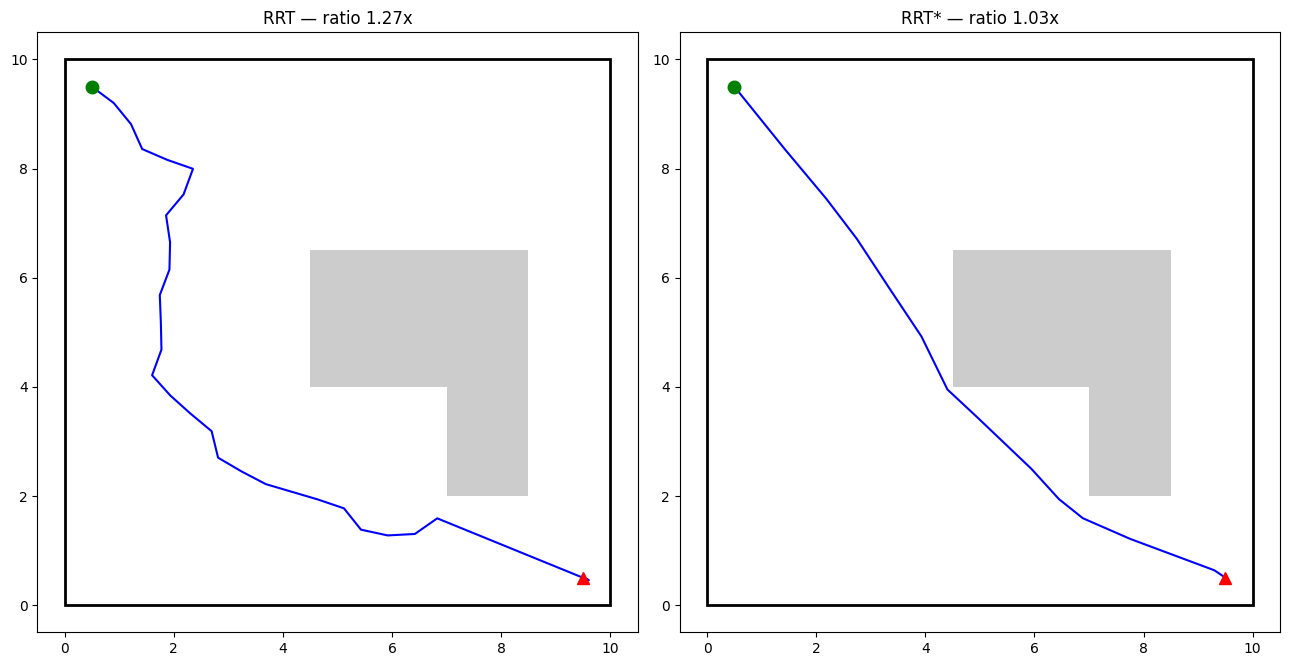

In [5]:
# --- RRT* (Karaman & Frazzoli 2011) ---
def rrtstar_plan(depart, but, max_iter=2000, pas=0.5, biais=0.1, rho=1.5, rng=None, bloque=None):
    """RRT* avec rewiring, execute sur le budget entier. Retourne {'chemin', 'noeuds'}."""
    rng = rng or random.Random()
    bloque = bloque or est_bloque
    noeuds = [depart]
    parent = [-1]
    cout = [0.0]
    cout_bat, meilleur_chemin = None, None

    def boule(i):
        """Noeuds dans la boule de rayon rho autour de noeuds[i]."""
        return [j for j in range(len(noeuds)) if j != i and dist(noeuds[i], noeuds[j]) <= rho]

    for _ in range(max_iter):
        cible = but if rng.random() < biais else (rng.uniform(*BOITE), rng.uniform(*BOITE))
        i = min(range(len(noeuds)), key=lambda k: dist(noeuds[k], cible))
        m = dist(noeuds[i], cible)
        if m < 1e-9:
            continue
        q = (noeuds[i][0] + pas / m * (cible[0] - noeuds[i][0]),
             noeuds[i][1] + pas / m * (cible[1] - noeuds[i][1]))
        if bloque(q) or segment_bloque(noeuds[i], q, bloque):
            continue
        # 1. meilleur parent dans la boule (min c(u) + d(u, q))
        ball = boule(i) or [i]
        u = min(ball, key=lambda k: cout[k] + dist(noeuds[k], q))
        if segment_bloque(noeuds[u], q, bloque):
            u = i  # repli : le segment i -> q est connu libre ci-dessus
        cout_q = cout[u] + dist(noeuds[u], q)
        parent.append(u); noeuds.append(q); cout.append(cout_q)
        # 2. rewiring : reparenter les y de la boule de q via q si c'est moins cher
        for y in boule(len(noeuds) - 1):
            # le re-parentage ne compte que si le segment q -> y est libre
            if cout_q + dist(q, noeuds[y]) < cout[y] and not segment_bloque(q, noeuds[y], bloque):
                parent[y] = len(noeuds) - 1
                cout[y] = cout_q + dist(q, noeuds[y])
        if dist(q, but) < 0.3:
            # le cout du chemin vers le but peut avoir CHANGÉ par rewiring : on le recalcule
            j, c = len(noeuds) - 1, 0.0
            while parent[j] != -1:
                c += dist(noeuds[j], noeuds[parent[j]])
                j = parent[j]
            if cout_bat is None or c < cout_bat:
                cout_bat = c
                chemin, j = [q], len(noeuds) - 1
                while parent[j] != -1:
                    j = parent[j]
                    chemin.append(noeuds[j])
                chemin.reverse()
                if not segment_bloque(q, but, bloque):
                    chemin.append(but)
                meilleur_chemin = chemin
    return {"chemin": meilleur_chemin, "noeuds": len(noeuds)}

res = rrtstar_plan(DEPART, BUT, max_iter=1500, rng=random.Random(0))
chemin_s = res['chemin']
print(f"RRT* : {res['noeuds']} noeuds, longueur {longueur(chemin_s):.2f} "
      f"(ratio vs borne inf. : {longueur(chemin_s) / BORNE_INF:.2f}x)")

fig, ax = plt.subplots(1, 2, figsize=(13, 6.5))
for a, (ch, tt) in zip(ax, [(chemin, 'RRT'), (chemin_s, 'RRT*')]):
    a.add_patch(plt.Rectangle((0, 0), 10, 10, fill=False, lw=2, ec='k'))
    for x0, y0, x1, y1 in OBSTACLES:
        a.add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fc='0.8'))
    xs, ys = zip(*ch)
    a.plot(xs, ys, 'b-', lw=1.5)
    a.plot(*DEPART, 'go', ms=9); a.plot(*BUT, 'r^', ms=9)
    a.set_xlim(-0.5, 10.5); a.set_ylim(-0.5, 10.5); a.set_aspect('equal')
    a.set_title(f"{tt} — ratio {longueur(ch) / BORNE_INF:.2f}x")
plt.tight_layout(); plt.show()

### Lecture du résultat

Même budget d'échantillons, même graine : le RRT\* a déjà une longueur nettement plus proche de la borne inférieure, et le tracé « lisse » les coudes que le RRT avait figés. Le théorème d'asymptotic optimality n'est pas une promesse sur un chemin unique — c'est une promesse sur la **tendance** quand $N$ croît. C'est exactement ce que la section suivante mesure.


## 4. Le contraste mesuré : qualité du chemin en fonction du budget $N$

Sur le terrain 3-obstacles, les deux algorithmes trouvent une solution et les sorties committées portent **1 210 noeuds acceptés** pour un budget de 1 500 itérations, des deux côtés : le budget n'a plus de prise sur la qualité, et le contraste serait illisible. On change de terrain — **une paroi verticale percée d'un créneau en bas** : toute trajectoire doit faire le détour par le créneau, la ligne droite y est bloquée, et la région du créneau est rare dans un tirage uniforme. C'est là que la qualité du parentage se joue.

Protocole : pour chaque budget $N \in \{300, 600, 1200, 2400, 4800\}$ et chaque graine parmi 5, on exécute les deux algorithmes **sur le budget entier** (l'exécution ne s'arrête pas au premier contact du but : le RRT\* peut encore l'améliorer par rewiring, et c'est précisément ce que l'on mesure) et on note le **ratio** longueur/borne inférieure du meilleur chemin obtenu. Médiane sur les 5 graines.

**Hypothèse à vérifier** : le RRT **plateau** (le premier chemin trouvé reste le meilleur — rien ne répare le parentage figé), le RRT\* **décroît** avec $N$ (le rewiring continue de lisser le passage du créneau).


| budget N | RRT (ratio) | RRT* (ratio) |
|---|---|---|
| 300 | 1.27 | 1.08 |
| 600 | 1.27 | 1.08 |
| 1200 | 1.27 | 1.04 |
| 2400 | 1.27 | 1.02 |
| 4800 | 1.27 | 1.02 |


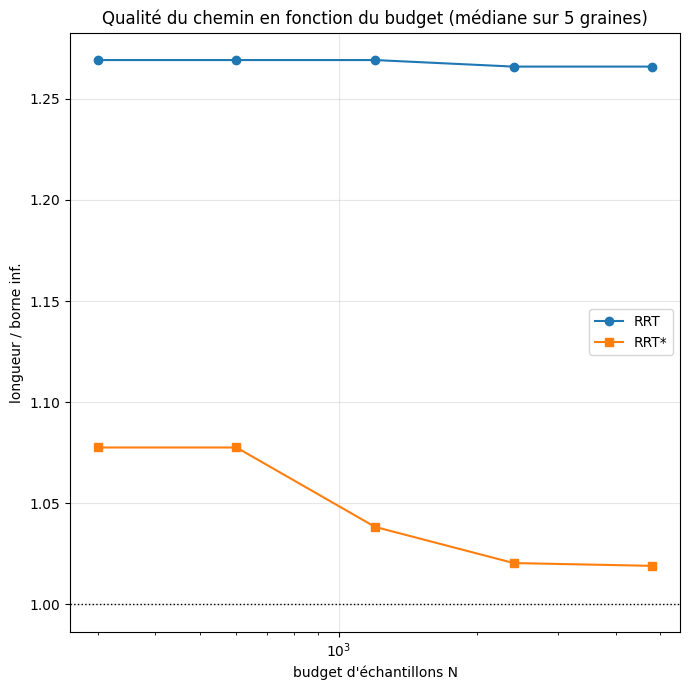

In [6]:
# --- Benchmark qualité vs budget (terrain : paroi + créneau) ---
MUR = (4.9, 3.5, 5.1, 10.0)  # paroi verticale, creneau en bas (hauteur 3.5)

def est_bloque_mur(pt):
    x, y = pt
    if not (0.0 <= x <= 10.0 and 0.0 <= y <= 10.0):
        return True
    x0, y0, x1, y1 = MUR
    return x0 <= x <= x1 and y0 <= y <= y1

DEPART_M, BUT_M = (0.5, 9.5), (9.5, 0.5)
BORNE_M = dist(DEPART_M, BUT_M)

BUDGETS = [300, 600, 1200, 2400, 4800]
GRAINES = [0, 1, 7, 42, 99]

def benchmark(plan, budgets, graines):
    stats = {}
    for N in budgets:
        ratios = []
        for g in graines:
            r = plan(DEPART_M, BUT_M, max_iter=N, rng=random.Random(g), bloque=est_bloque_mur)
            if r['chemin']:
                ratios.append(longueur(r['chemin']) / BORNE_M)
        stats[N] = sorted(ratios)[len(ratios) // 2] if ratios else None
    return stats

res_rrt = benchmark(rrt_plan, BUDGETS, GRAINES)
res_rrtstar = benchmark(rrtstar_plan, BUDGETS, GRAINES)

print("| budget N | RRT (ratio) | RRT* (ratio) |")
print("|---|---|---|")
for N in BUDGETS:
    print(f"| {N} | {res_rrt[N]:.2f} | {res_rrtstar[N]:.2f} |")

fig, ax = plt.subplots()
ax.plot(BUDGETS, [res_rrt[N] for N in BUDGETS], 'o-', label='RRT')
ax.plot(BUDGETS, [res_rrtstar[N] for N in BUDGETS], 's-', label='RRT*')
ax.axhline(1.0, color='k', ls=':', lw=1)
ax.set_xscale('log')
ax.set_xlabel('budget d\'échantillons N'); ax.set_ylabel('longueur / borne inf.')
ax.set_title('Qualité du chemin en fonction du budget (médiane sur 5 graines)')
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

### Lecture du résultat

Lisez la table : sur ce terrain, le RRT trouve d'abord un chemin qui passe « n'importe comment » dans le créneau, et **aucun échantillon supplémentaire ne le répare** — la courbe est plate. Le RRT*, lui, **décroît puis sature** au plancher de résolution (la table montre deux paliers, 300↔600 et 2400↔4800) : le rewiring re-parente progressivement les nœuds du créneau sur de meilleurs voisins, et le chemin converge vers le détour optimal. C'est la signature mesurée de l'asymptotic optimality — et l'écart entre les deux courbes est le prix du parentage figé. Le coût du rewiring : des balayages de boule à chaque insertion ($O(N)$ par nœud ici ; les implémentations industrielles utilisent des structures de voisinage, cf. Search-02b).


## 5. Exercices


### Exercice 1 : la fonction `plus_proche` au carré

**Énoncé** : dans `rrt_plan`, la recherche du nœud le plus proche balaye la liste entière à chaque itération — $O(N^2)$ au total. Écrivez `plus_proche_index(p, noeuds)` qui renvoie l'indice du nœud le plus proche de `p` (et `None` si `noeuds` est vide), en une seule passe.

```python
# Indice : `min` avec `key` et un garde-fou pour la liste vide.
```


In [7]:
def plus_proche_index(p, noeuds):
    # TODO etudiant : index du noeud le plus proche de p, None si noeuds est vide
    print("Exercice a completer : plus_proche_index")
    return None

# controle positif (doit donner 0 sur cette liste trivialement proche) :
assert plus_proche_index((0.1, 0.1), [(0.0, 0.0), (5.0, 5.0), (9.0, 9.0)]) in (None, 0)

Exercice a completer : plus_proche_index


### Exercice 2 : le choix du parent dans la boule

**Énoncé** : écrivez `meilleur_parent(x, boule, noeuds, cout)` qui renvoie l'indice $u \in$ `boule` minimisant $c(u) + d(u, x)$ — la règle d'insertion du RRT\* (section 3, étape 1).

```python
# Indice : c'est un `min` avec une `key` qui combine le coût cumulé et la distance.
```


In [8]:
def meilleur_parent(x, boule, noeuds, cout):
    # TODO etudiant : indice u minimisant cout[u] + dist(noeuds[u], x)
    print("Exercice a completer : meilleur_parent")
    return None

# controle positif : parmi deux candidats, le moins cher gagne
u = meilleur_parent((2.0, 0.0), [0, 1], [(0.0, 0.0), (1.9, 0.0)], [0.0, 5.0])
assert u in (None, 1)

Exercice a completer : meilleur_parent


### Exercice 3 : le goulet étroit (mesure)

**Énoncé** : remplacez le terrain par un **corridor** : deux obstacles qui laissent un passage de largeurs $w \in \{0.8, 1.6, 3.2\}$. Pour chaque largeur, mesurez le ratio des deux algorithmes à $N = 1200$ (3 graines). **Hypothèse à formuler avant de lancer** : que devient l'écart RRT / RRT\* quand le corridor se resserre ? Lancez, puis reliez le résultat au mécanisme de rewiring (le corridor restreint les boules de voisinage : qui en paie le prix ?).

```python
# Indice : `OBSTACLES` est une simple liste — paramétrez-la par la largeur w.
```


In [9]:
# TODO etudiant : bench corridor w in {0.8, 1.6, 3.2}, N=1200, 3 graines,
# hypothese formulee ci-dessus dans une cellule markdown, puis mesure
print("Exercice a completer : bench corridor")
ratio_rrt_par_w = None   # TODO etudiant : dict w -> ratio RRT
ratio_rrtstar_par_w = None  # TODO etudiant : dict w -> ratio RRT*

Exercice a completer : bench corridor


## Références

- Russell, S., & Norvig, P. (2021). *Artificial Intelligence: A Modern Approach* (4e éd.) — pour le cadrage du motion planning dans le champ de l'IA.
- LaValle, S. M. (1998). *Rapidly-exploring Random Trees : A New Tool for Path Planning*. Technical Report TR98-14, University of Iowa.
- Karaman, S., & Frazzoli, E. (2011). *Sampling-based Algorithms for Optimal Motion Planning*. arXiv:1105.1186.


## Conclusion

- **RRT** (LaValle 1998) : l'échantillonnage remplace l'énumération — complétude dans les espaces continus, au prix de chemins dont la qualité **stagne** quand le budget croît.
- **RRT\*** (Karaman & Frazzoli 2011) : le rewiring (meilleur parent dans la boule + reparentage) transforme la complétude en **asymptotic optimality** — mesurée ici comme décroissance continue du ratio longueur/borne inférieure.
- **Point de vigilance** : le théorème est une propriété en $N \to \infty$ ; à budget fixe, l'avantage dépend du terrain (boules de voisinage, goulets) — c'est l'objet de l'exercice 3.
- **Suite** : la recherche **informée** (Search-03) revient sur les espaces discrets avec des heuristiques — l'écho discret du « viser le but » du biais RRT.


## À retenir

1. **La qualité se mesure en ratio contre la borne inférieure** : la borne $b$ — la distance à vol d'oiseau — vaut **12,73** sur ce terrain — c'est le plancher de toute trajectoire, obstacles ou non. Le ratio longueur/borne rend la dette de qualité comparable d'un terrain et d'une échelle à l'autre.
2. **Le budget mesuré de RRT (LaValle 1998)** : 1210 nœuds, longueur **16,12** (ratio **1,27×**) — chaque nœud est rattaché à son plus proche voisin **sans jamais réexaminer** les décisions passées.
3. **Le budget mesuré de RRT\* (Karaman & Frazzoli 2011)** : même budget, même graine — **13,07** (ratio **1,03×**) : les coudes que RRT avait figés sont révisés en cours de construction.
4. **La signature mesurée de l'asymptotic optimality** : la colonne RRT reste **plate à 1,27** du budget 300 au budget 4800 ; RRT\* décroît **1,08 → 1,02** puis sature au plancher de résolution (deux paliers, 300↔600 et 2400↔4800).
5. **Le prix du rewiring** : un balayage de boule à chaque insertion, $O(N)$ par nœud dans cette implémentation — les implémentations industrielles le réduisent par des structures de voisinage.

## Vérifiez votre compréhension

1. Pourquoi la qualité d'un chemin se mesure-t-elle en ratio contre la borne inférieure (12,73) plutôt qu'en longueur absolue ?
2. Sur le benchmark de la section 4, la colonne RRT reste à 1,27 du budget 300 au budget 4800. Que révèle cette constance sur le mécanisme ?
3. RRT\* passe de 1,08 (N=300) à 1,02 (N=2400) puis cesse de décroître. Pourquoi s'arrête-t-il au lieu d'atteindre 1,00 ?
4. À budget et graine égaux, quel mécanisme précis fait passer la longueur de 16,12 (RRT) à 13,07 (RRT\*) ?

<details><summary>Réponses</summary>

1. La distance à vol d'oiseau est le minimum atteignable par toute trajectoire sur ce terrain : le ratio isole la dette de qualité (détours et coudes) indépendamment de la taille du monde, et permet de comparer deux planificateurs ou deux terrains.
2. RRT choisit le parent au moment de l'insertion et ne le réexamine jamais : le premier chemin qui franchit le créneau reste tel quel. Des échantillons supplémentaires allongent l'arbre, pas le chemin — la courbe est plate par construction.
3. Le théorème d'optimalité est une propriété en $N \to \infty$. À budget fini, la résolution (pas de 0,5 entre nœuds, rayon des boules de voisinage) impose un plancher : le chemin converge vers le meilleur détour que cette résolution peut exprimer.
4. Le rewiring : à chaque insertion, RRT\* cherche le meilleur parent dans la boule de voisinage **et** reparente les nœuds existants vers le nouveau venu quand cela raccourcit leur coût — les coudes figés de RRT sont progressivement révisés.

</details>

## Pour aller plus loin

- **Carnet suivant** : [Search-03-Informed](Search-03-Informed.ipynb) — la recherche informée ramène les heuristiques dans les espaces discrets : l'écho discret du biais « viser le but » de RRT.
- **Dans la même série** : [Search-02-Uninformed](Search-02-Uninformed.ipynb) (le cadre frontière FIFO/LIFO/priorité que l'échantillonnage étend au continu) et [Search-02b-NetworkX](Search-02b-NetworkX.ipynb) (les mêmes terrains sous networkx).
- **Carnet voisin d'une autre série** : [Sudoku-02-DancingLinks-Python](../../Sudoku/Sudoku-02-DancingLinks-Python.ipynb) — l'exploration exhaustive d'un espace de solutions discret, le contrepoint exact du planificateur par échantillonnage.
- **Lectures** : les trois références citées en fin de carnet — LaValle (1998, TR98-14) pour RRT, Karaman & Frazzoli (2011, arXiv:1105.1186) pour RRT\* et la preuve d'optimalité asymptotique, Russell & Norvig (2021) pour le cadrage du motion planning.